# 03 · Thiết kế kiểm định và thí nghiệm rò rỉ

**Mục tiêu.** Đo chất lượng mô hình một cách trung thực **chỉ bằng tập train**, để chọn siêu tham số và mô hình mà không chạm tới test. Notebook có ba phần:

1. **Sơ đồ rolling-origin theo ngày:** 6 khối ngày liên tiếp trên train, tạo 5 fold với cửa sổ huấn luyện mở rộng dần.
2. **Dò siêu tham số** bằng `GridSearchCV` trên chính bộ chia đó; xem độ dao động giữa các fold và mức lạc quan do việc chọn siêu tham số.
3. **Thí nghiệm rò rỉ:** cùng mô hình, cùng siêu tham số, so k-fold ngẫu nhiên 5×3 với rolling-origin, để thấy chia sai cách làm điểm số cao giả đến mức nào.

> Notebook **có huấn luyện mô hình** (khoảng 980 lần, mất 1–2 phút) nhưng chỉ trên tập train. Mô hình cuối cùng và đánh giá trên test nằm ở `04_models`.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # chạy được từ notebooks/ hoặc từ gốc repo
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
warnings.filterwarnings("ignore", category=FutureWarning)

from config import DATA_FILE, SEED
import plots as P

import features as F
import splits as S
import evaluate as E
import pipeline as PL

df = F.build_dataset(DATA_FILE)
train, test = S.split_train_test(df)
cv = S.RollingOriginByDate(n_blocks=6)

## 1. Sơ đồ rolling-origin
**Vì sao rolling-origin.** Mô hình sẽ được dùng để dự báo ngày mai từ dữ liệu đến hôm nay. Rolling-origin mô phỏng đúng điều đó: mỗi fold chỉ huấn luyện trên các ngày **trước** và kiểm định trên các ngày **sau**. Đề yêu cầu dùng cách này cho dữ liệu chuỗi thời gian.

**Vì sao chia theo ngày, không theo dòng.** Mọi tổ trong cùng một ngày phải nằm cùng một phía. `TimeSeriesSplit` của sklearn cắt theo chỉ số dòng nên có thể chia đôi một ngày, để một số tổ của ngày d ở train và các tổ còn lại ở validate.

**Vì sao 6 khối và cửa sổ mở rộng.**
- 47 ngày train chia thành 6 khối khoảng 8 ngày. Ít khối hơn thì có quá ít fold để đo độ dao động; nhiều khối hơn thì mỗi khối validate chỉ còn vài ngày, điểm số rất nhiễu.
- Cửa sổ **mở rộng** (fold sau huấn luyện trên mọi ngày trước đó) thay vì cửa sổ trượt cố định, vì dữ liệu ít: bỏ bớt các ngày cũ sẽ làm mô hình còn ít dữ liệu hơn.
- Khối 0 chỉ dùng để huấn luyện, nên không có dự báo out-of-fold cho 8 ngày đầu.

,fold,train_from,train_to,val_from,val_to,n_train,n_val,n_days_train,n_days_val
0,1,2015-01-01,2015-01-10,2015-01-11,2015-01-19,170,167,8,8
1,2,2015-01-01,2015-01-19,2015-01-20,2015-01-28,337,161,16,8
2,3,2015-01-01,2015-01-28,2015-01-29,2015-02-07,498,157,24,8
3,4,2015-01-01,2015-02-07,2015-02-08,2015-02-16,655,148,32,8
4,5,2015-01-01,2015-02-16,2015-02-17,2015-02-25,803,140,40,7


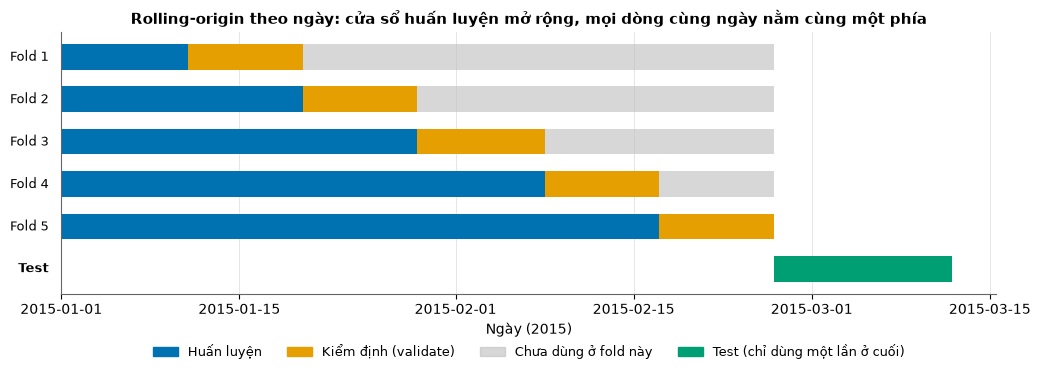

In [2]:
S.assert_cv_folds_valid(cv, train)
display(cv.fold_table(train))
fig = P.plot_rolling_origin(train, test, cv); plt.show()

**Nhận xét.**
- `assert_cv_folds_valid` xác nhận ở mọi fold: ngày validate đứng sau mọi ngày huấn luyện và không ngày nào bị chia đôi.
- Tập huấn luyện tăng dần từ 170 dòng (8 ngày) ở fold 1 lên 803 dòng (40 ngày) ở fold 5. **Fold 1 rất nhỏ**: mô hình chỉ thấy 8 ngày, nhưng khi lấy trung bình qua 5 fold, fold này được tính ngang hàng với các fold khác.
- Mỗi khối validate có 7–8 ngày (140–167 dòng). Fold 5 (17/02–25/02) rơi đúng giai đoạn tỷ lệ trượt cao nhất trong EDA.
- Tổng cộng 39 ngày train có dự báo out-of-fold (khối 1–5). Các notebook sau dùng các dự báo này để chọn chính sách và tính chi phí mà không cần đụng tới test.
- Test (xanh lá trên hình) nằm hoàn toàn sau mọi fold và không được dùng ở notebook này.

## 2. Dò siêu tham số bằng `GridSearchCV` + rolling-origin (cả hai kịch bản)
**Vì sao làm theo cách này.**
- `GridSearchCV` nhận chính bộ chia rolling-origin ở trên, nên siêu tham số được chọn theo đúng cách mô hình sẽ được dùng.
- Mỗi fold, `GridSearchCV` **nhân bản toàn bộ pipeline** (median, chuẩn hoá, one-hot, mô hình) và `fit` lại từ đầu trên phần train của fold đó. Đây là chỗ bảo đảm không có thống kê nào của phần validate lọt vào bước tiền xử lý.
- Tiêu chí chọn là **PR-AUC** (`average_precision`): lớp dương chỉ khoảng 27%, và quyết định là *xếp hạng* xem tổ nào đáng cảnh báo nhất, nên cần chỉ số đo chất lượng xếp hạng ở lớp dương. Accuracy không dùng được (luôn đoán "đạt" đã được 73%).
- Lưới **nhỏ** (5–25 cấu hình mỗi mô hình) vì train chỉ có 943 dòng; lưới lớn dễ chọn trúng cấu hình "may mắn" trên vài fold.

In [3]:
sel = {s: E.select_models(train, s, cv) for s in ("A", "B")}
pd.DataFrame([{"scenario": s, "model": m, "params": E.params_to_str(p)} for s in sel for m, p in sel[s]["best"].items()])

,scenario,model,params
0,A,DecisionTree,"{'clf__max_depth': 4, 'clf__min_samples_leaf': 10}"
1,A,SVM_RBF,"{'clf__C': 0.1, 'clf__gamma': 'scale'}"
2,A,MLP,"{'clf__alpha': 0.1, 'clf__hidden_layer_sizes': (8,)}"
3,A,Logistic,{'clf__C': 100.0}
4,A,RandomForest,"{'clf__max_depth': 4, 'clf__min_samples_leaf': 3}"
5,B,DecisionTree,"{'clf__max_depth': 5, 'clf__min_samples_leaf': 20}"
6,B,SVM_RBF,"{'clf__C': 1.0, 'clf__gamma': 0.03}"
7,B,MLP,"{'clf__alpha': 1.0, 'clf__hidden_layer_sizes': (64,)}"
8,B,Logistic,{'clf__C': 10.0}
9,B,RandomForest,"{'clf__max_depth': 8, 'clf__min_samples_leaf': 2}"


**Nhận xét.**
- Ở kịch bản A, các cấu hình được chọn đều **đơn giản**: Random Forest và cây chỉ sâu 4 tầng, SVM chọn `C` nhỏ nhất (phạt mạnh), MLP chọn mạng nhỏ nhất `(8,)`. Điều này hợp với dữ liệu ít: mô hình phức tạp hơn không giúp ích trên các fold.
- Một số giá trị nằm ở **biên lưới** (ví dụ SVM `C = 0,1` ở biên dưới, Logistic `C = 100` ở biên trên). Khi đó chưa chắc giá trị tốt nhất nằm trong lưới; `04_models` kiểm tra biên và thử thêm một nấc ra ngoài.
- Kịch bản B chọn các cấu hình phức tạp hơn (Random Forest sâu 8, MLP `(64,)`), có thể vì ba biến thêm vào mang nhiều tín hiệu hơn.

### Thiên lệch do chọn siêu tham số
Điểm CV của cấu hình tốt nhất được tính trên **chính các fold dùng để chọn nó**, nên hơi lạc quan: trong nhiều cấu hình, cấu hình thắng có thể chỉ là cấu hình gặp may trên 5 fold này. Cách loại bỏ hẳn là nested CV (thêm một vòng kiểm định bên ngoài), nhưng với 47 ngày train thì không đủ dữ liệu. Bảng dưới đo mức lạc quan bằng cách so cấu hình tốt nhất với cấu hình trung vị của lưới (kịch bản A).

In [4]:
g = sel["A"]["grid"]
bias = g.groupby("model")["average_precision_mean"].agg(so_cau_hinh="size", tot_nhat="max", trung_vi="median", te_nhat="min")
bias["tot_nhat_tru_trung_vi"] = bias["tot_nhat"] - bias["trung_vi"]
bias.rename(index=PL.MODEL_LABELS).sort_values("tot_nhat", ascending=False).round(3)

,so_cau_hinh,tot_nhat,trung_vi,te_nhat,tot_nhat_tru_trung_vi
model,,,,,
Random Forest,15,0.574,0.563,0.551,0.011
SVM (RBF),12,0.544,0.505,0.459,0.039
Cây quyết định,25,0.503,0.479,0.415,0.024
Hồi quy logistic,5,0.493,0.481,0.473,0.011
Mạng nơ-ron (MLP),20,0.485,0.461,0.446,0.024


**Nhận xét.**
- Mức chênh giữa cấu hình tốt nhất và cấu hình trung vị là thước đo thô của độ lạc quan: SVM khoảng 0,04, cây khoảng 0,02, Random Forest và Logistic chỉ khoảng 0,01 (riêng Logistic có ít chỗ để lạc quan vì lưới chỉ có 5 cấu hình).
- **Random Forest vững nhất:** ngay cả cấu hình *trung vị* của nó vẫn cao hơn cấu hình *tốt nhất* của mọi mô hình khác. Vì vậy việc Random Forest đứng đầu không phải do may mắn khi chọn siêu tham số.
- Khi báo cáo PR-AUC CV, nên ghi rằng con số có thể lạc quan ở mức vài phần trăm, nhiều nhất với SVM.

### Độ dao động giữa các fold và tỷ lệ trượt
Đề yêu cầu báo cáo độ dao động giữa các fold, không chỉ trung bình. Có một điểm cần lưu ý: **PR-AUC phụ thuộc tỷ lệ lớp dương**. Một mô hình đoán bừa có PR-AUC xấp xỉ tỷ lệ trượt của fold đó, nên fold có nhiều ca trượt sẽ có PR-AUC cao hơn dù mô hình không tốt hơn.

Bảng thứ nhất là PR-AUC thô của từng fold (kịch bản A). Bảng thứ hai chia PR-AUC cho tỷ lệ trượt của fold, tức là **mô hình tốt gấp bao nhiêu lần đoán bừa**; giá trị 1 nghĩa là không hơn đoán bừa.

In [5]:
_, base_folds = E.baseline_oof(train, cv)
fa = pd.concat([sel["A"]["folds"], base_folds], ignore_index=True)
fa["lift"] = fa["average_precision"] / fa["prevalence"]
cols = ["B1", "B2"] + PL.MODEL_NAMES
prev = fa.groupby("fold")["prevalence"].first()

def by_fold(value):
    t = fa.pivot_table(index="fold", columns="model", values=value)[cols]
    t.loc["TB"], t.loc["độ lệch chuẩn"] = t.mean(), t.std(ddof=1)
    t.insert(0, "ty_le_truot", list(prev) + [prev.mean(), prev.std(ddof=1)])
    return t.rename(columns=P.SHORT).round(3)

print("PR-AUC thô theo fold (kịch bản A):")
display(by_fold("average_precision"))
print("PR-AUC / tỷ lệ trượt (số lần tốt hơn đoán bừa):")
by_fold("lift")

PR-AUC thô theo fold (kịch bản A):


model,ty_le_truot,B1 (hôm qua trượt),B2 (mọi tổ finishing),Cây quyết định,SVM (RBF),Mạng nơ-ron (MLP),Hồi quy logistic,Random Forest
fold,,,,,,,,
1,0.257,0.391,0.453,0.588,0.595,0.479,0.422,0.691
2,0.205,0.298,0.411,0.491,0.581,0.423,0.559,0.576
3,0.229,0.535,0.358,0.366,0.382,0.426,0.356,0.385
4,0.331,0.465,0.465,0.580,0.511,0.507,0.531,0.545
5,0.407,0.527,0.588,0.490,0.648,0.592,0.596,0.675
TB,0.286,0.443,0.455,0.503,0.544,0.485,0.493,0.574
độ lệch chuẩn,0.083,0.100,0.085,0.090,0.103,0.069,0.100,0.123


PR-AUC / tỷ lệ trượt (số lần tốt hơn đoán bừa):


model,ty_le_truot,B1 (hôm qua trượt),B2 (mọi tổ finishing),Cây quyết định,SVM (RBF),Mạng nơ-ron (MLP),Hồi quy logistic,Random Forest
fold,,,,,,,,
1,0.257,1.518,1.761,2.284,2.310,1.861,1.640,2.683
2,0.205,1.454,2.006,2.397,2.836,2.065,2.727,2.810
3,0.229,2.335,1.561,1.595,1.666,1.858,1.553,1.681
4,0.331,1.403,1.405,1.751,1.544,1.531,1.603,1.647
5,0.407,1.294,1.444,1.204,1.593,1.454,1.464,1.658
TB,0.286,1.601,1.635,1.846,1.990,1.754,1.797,2.096
độ lệch chuẩn,0.083,0.419,0.249,0.495,0.566,0.254,0.524,0.596


**Nhận xét.**
- Tỷ lệ trượt ở các khối validate thay đổi mạnh, từ khoảng 20% (fold 2) đến khoảng 41% (fold 5). Vì vậy một phần lớn độ lệch chuẩn của PR-AUC thô đến từ việc **các fold có tỷ lệ trượt khác nhau**, không chỉ do mô hình lúc tốt lúc kém.
- PR-AUC thô của Random Forest cao ở fold 5 (khoảng 0,68), nhưng sau khi chia cho tỷ lệ trượt thì fold 5 lại là một trong những fold **kém nhất** (khoảng 1,7 lần đoán bừa).
- **Lợi thế của mô hình thu hẹp dần về cuối train:** Random Forest tốt gấp khoảng 2,7–2,8 lần đoán bừa ở fold 1–2, nhưng chỉ khoảng 1,7 lần ở fold 3–5. Trong khi đó B1 ("hôm qua trượt") dao động 1,3–2,3 lần, và ở fold 3 còn cao hơn hẳn Random Forest (2,3 so với 1,7 lần).
- Hệ quả cho báo cáo: (1) khi nói về độ dao động, nên tách phần do tỷ lệ trượt thay đổi; (2) giai đoạn gần test nhất là giai đoạn mô hình hơn baseline ít nhất, điều này phù hợp với kết quả ở `05_cost` rằng mô hình chưa hơn B1 có ý nghĩa thống kê.

## 3. Thí nghiệm rò rỉ: k-fold ngẫu nhiên 5×3 và rolling-origin
**Câu hỏi.** Nếu bỏ qua yếu tố thời gian và chia train một cách ngẫu nhiên (k-fold phân tầng 5 fold, lặp 3 lần), điểm số sẽ đẹp hơn bao nhiêu? Cùng mô hình, cùng siêu tham số đã chọn ở trên, chỉ thay cách chia.

**Ba cơ chế khiến chia ngẫu nhiên lạc quan với dữ liệu này:**
1. **Qua đặc trưng trễ.** Đặc trưng trễ của ngày d+1 chứa kết quả của ngày d (ví dụ `lag1_gap` của ngày d+1 chính là `gap` của ngày d). Khi chia ngẫu nhiên, ngày d có thể nằm ở validate còn ngày d+1 nằm ở train: mô hình được học trên một dòng mà đặc trưng của nó **chứa đáp án** của chính dòng đang được kiểm tra.
2. **Cùng ngày.** Các tổ trong cùng một ngày chịu chung điều kiện (mã hàng, kế hoạch, sự cố chung), thậm chí có vài dòng trùng gần như hoàn toàn giữa các tổ. Chia ngẫu nhiên đặt các tổ của cùng một ngày ở cả hai phía, nên mô hình "biết trước" phần nào tình hình của ngày đang kiểm tra.
3. **Không dừng theo thời gian.** Tỷ lệ trượt tăng mạnh giữa tháng 2. Chia ngẫu nhiên trộn giai đoạn này vào cả train lẫn validate, nên mô hình luôn được thấy mẫu của mọi giai đoạn. Khi vận hành thật, mô hình phải đối mặt với giai đoạn mới mà nó chưa từng thấy.

Ô dưới đo trực tiếp hai cơ chế đầu: với mỗi dòng validate, (1) dòng **kế tiếp** của cùng cặp tổ-bộ phận (dòng có đặc trưng trễ chứa kết quả của dòng này) có nằm trong train không, và (2) **ngày** của dòng đó có xuất hiện trong train không.

In [6]:
from sklearn.model_selection import RepeatedStratifiedKFold

nxt = train.groupby(F.KEY, sort=False)["row_id"].shift(-1)   # row_id của dòng kế tiếp cùng cặp
def exposure(splits):
    lag_leak, same_day = [], []
    for tr, va in splits:
        tr_ids, tr_dates = set(train["row_id"].iloc[tr]), set(train["date"].iloc[tr])
        nx = nxt.iloc[va].dropna()
        lag_leak.append(nx.isin(tr_ids).mean())
        same_day.append(train["date"].iloc[va].isin(tr_dates).mean())
    return np.mean(lag_leak), np.mean(same_day)

rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
pd.DataFrame(
    [exposure(rskf.split(train, train["miss"])), exposure(cv.split(train))],
    index=["k-fold ngẫu nhiên 5×3", "rolling-origin theo ngày"],
    columns=["dòng kế tiếp nằm trong train (cơ chế 1)", "ngày của dòng có trong train (cơ chế 2)"],
).map(lambda v: f"{v:.0%}")

,dòng kế tiếp nằm trong train (cơ chế 1),ngày của dòng có trong train (cơ chế 2)
k-fold ngẫu nhiên 5×3,80%,100%
rolling-origin theo ngày,0%,0%


**Nhận xét.**
- Với k-fold ngẫu nhiên, khoảng 4/5 dòng validate có dòng kế tiếp (chứa kết quả của chính nó trong đặc trưng trễ) nằm trong train, và **mọi** dòng validate (100%) có các tổ khác cùng ngày nằm trong train.
- Với rolling-origin, cả hai con số đều bằng 0%: dòng kế tiếp luôn nằm ở validate hoặc ở tương lai, và không ngày nào nằm ở cả hai phía. Đây là lý do rolling-origin không bị hai cơ chế này.
- Cơ chế 3 (không dừng) không đo được bằng một con số như vậy, nhưng thể hiện qua bảng tỷ lệ trượt theo fold ở mục 2.

In [7]:
rand = pd.concat([E.random_cv_folds(m, s, sel[s]["best"][m], train) for s in sel for m in PL.MODEL_NAMES], ignore_index=True)
roll = pd.concat([sel[s]["folds"] for s in sel], ignore_index=True)
rows = []
for scheme, tab in (("random", rand), ("rolling", roll)):
    for (s, m), g in tab.groupby(["scenario", "model"]):
        for metric in E.METRICS:
            rows.append({"scenario": s, "model": m, "scheme": scheme, "metric": metric,
                         "mean": g[metric].mean(), "std": g[metric].std(ddof=1), "n_folds": len(g)})
summ = pd.DataFrame(rows)

def leak_table(metric):
    t = summ[summ.metric == metric].pivot_table(index=["scenario", "model"], columns="scheme", values=["mean", "std"])
    t.columns = [f"{a}_{b}" for a, b in t.columns]
    t["chenh_ngau_nhien_tru_rolling"] = t["mean_random"] - t["mean_rolling"]
    t = t[["mean_random", "std_random", "mean_rolling", "std_rolling", "chenh_ngau_nhien_tru_rolling"]]
    return t.rename(index=PL.MODEL_LABELS, level="model").round(3)

print(f"Tỷ lệ trượt trung bình ở phần validate: ngẫu nhiên {rand.prevalence.mean():.3f} | rolling {roll.prevalence.mean():.3f}")
print(f"Số dòng huấn luyện trung bình mỗi fold: ngẫu nhiên {len(train) * 4 / 5:.0f} | rolling {np.mean([len(tr) for tr, _ in cv.split(train)]):.0f}")
print("PR-AUC (TB ± độ lệch chuẩn qua fold; ngẫu nhiên: 15 fold, rolling: 5 fold):")
display(leak_table("average_precision"))
print("ROC-AUC:")
leak_table("roc_auc")

Tỷ lệ trượt trung bình ở phần validate: ngẫu nhiên 0.269 | rolling 0.286
Số dòng huấn luyện trung bình mỗi fold: ngẫu nhiên 754 | rolling 493
PR-AUC (TB ± độ lệch chuẩn qua fold; ngẫu nhiên: 15 fold, rolling: 5 fold):


mean_random  std_random  mean_rolling  std_rolling  chenh_ngau_nhien_tru_rolling
scenario model                                                                                              
A        Cây quyết định           0.531       0.052         0.503        0.090                         0.028
         Hồi quy logistic         0.557       0.058         0.493        0.100                         0.064
         Mạng nơ-ron (MLP)        0.512       0.077         0.485        0.069                         0.026
         Random Forest            0.619       0.059         0.574        0.123                         0.044
         SVM (RBF)                0.571       0.075         0.544        0.103                         0.028
B        Cây quyết định           0.577       0.053         0.486        0.100                         0.091
         Hồi quy logistic         0.615       0.071         0.579        0.085                         0.036
         Mạng nơ-ron (MLP)        0.540       0.092         0.495        0.101                         0.045
         Random Forest            0.681       0.050         0.590        0.127                         0.092
         SVM (RBF)                0.624       0.070         0.566        0.101                         0.058

ROC-AUC:


mean_random  std_random  mean_rolling  std_rolling  chenh_ngau_nhien_tru_rolling
scenario model                                                                                              
A        Cây quyết định           0.758       0.030         0.712        0.067                         0.046
         Hồi quy logistic         0.789       0.028         0.727        0.025                         0.062
         Mạng nơ-ron (MLP)        0.743       0.045         0.718        0.041                         0.025
         Random Forest            0.801       0.040         0.766        0.045                         0.035
         SVM (RBF)                0.790       0.039         0.756        0.051                         0.033
B        Cây quyết định           0.812       0.034         0.737        0.032                         0.075
         Hồi quy logistic         0.832       0.028         0.770        0.042                         0.061
         Mạng nơ-ron (MLP)        0.774       0.058         0.719        0.058                         0.055
         Random Forest            0.850       0.029         0.793        0.030                         0.057
         SVM (RBF)                0.835       0.035         0.776        0.028                         0.059

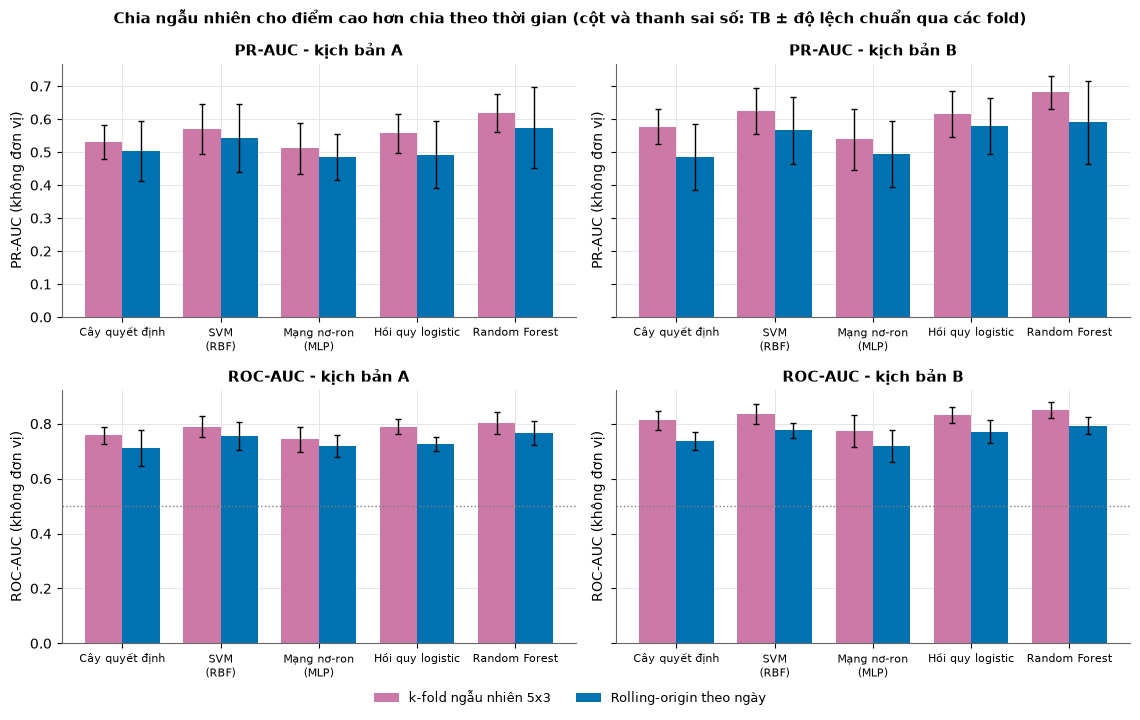

In [8]:
fig = P.plot_leakage(summ); plt.show()

**Cách đọc và nhận xét.**
- Ở **cả 10 tổ hợp** (5 mô hình × 2 kịch bản), chia ngẫu nhiên đều cho điểm cao hơn rolling-origin: PR-AUC cao hơn khoảng 0,03–0,09, ROC-AUC cao hơn khoảng 0,03–0,08. Nếu dùng chia ngẫu nhiên, nhóm sẽ báo cáo một mô hình tốt hơn thực tế.
- **Không nên coi chênh lệch PR-AUC là cận trên của hiệu ứng rò rỉ.** Ngoài rò rỉ, hai cách chia còn khác nhau ở hai điểm, và chúng tác động **ngược chiều**:
  - chia ngẫu nhiên huấn luyện trên nhiều dòng hơn (khoảng 754 so với trung bình khoảng 493 của rolling), làm điểm ngẫu nhiên cao hơn;
  - phần validate của rolling có tỷ lệ trượt cao hơn (xem dòng in ở trên), làm PR-AUC của rolling cao hơn, tức là che bớt chênh lệch.
  Vì vậy chênh lệch PR-AUC có thể lớn hơn hoặc nhỏ hơn hiệu ứng rò rỉ thật.
- **Bằng chứng chắc hơn là ROC-AUC**, vì ROC-AUC không phụ thuộc tỷ lệ lớp dương. ROC-AUC vẫn chênh 0,03–0,08 ở mọi tổ hợp, nên kết luận "chia ngẫu nhiên lạc quan" vững, dù độ lớn chính xác của riêng phần rò rỉ không tách được.
- Kịch bản B có chênh lệch lớn hơn A ở hầu hết mô hình (ví dụ Random Forest PR-AUC +0,092 so với +0,044). Một cách hiểu: các biến thêm vào ở B (`incentive`, `over_time`) gắn với từng ngày cụ thể, nên chia ngẫu nhiên khai thác cơ chế "cùng ngày" mạnh hơn.
- Với PR-AUC, độ lệch chuẩn của chia ngẫu nhiên thường nhỏ hơn rolling (với ROC-AUC thì hai bên gần nhau). Tuy vậy 15 fold ngẫu nhiên không độc lập (3 lần lặp dùng chung dữ liệu), nên con số này đánh giá thấp độ bất định thật. Các fold rolling-origin cũng không độc lập, vì tập huấn luyện của chúng lồng nhau.

## 4. Tổng kết

| Quyết định | Lý do |
|---|---|
| Rolling-origin theo ngày, 6 khối, cửa sổ mở rộng | Mô phỏng dự báo ngày mai; không chia đôi một ngày; giữ tối đa dữ liệu huấn luyện |
| Dò siêu tham số bằng `GridSearchCV` trên cùng bộ chia, tiêu chí PR-AUC | Pipeline fit lại ở mỗi fold; PR-AUC đo chất lượng xếp hạng ở lớp dương |
| Lưới nhỏ, ưu tiên mô hình đơn giản | Dữ liệu ít; hạn chế chọn trúng cấu hình gặp may |
| Không dùng k-fold ngẫu nhiên | Rò rỉ qua đặc trưng trễ và cùng ngày; ROC-AUC lạc quan thêm 0,03–0,08 |

Các con số cần mang theo sang báo cáo: độ lệch chuẩn qua fold cùng cỡ với chênh lệch giữa các mô hình; một phần dao động đến từ tỷ lệ trượt thay đổi giữa các fold; lợi thế của mô hình so với đoán bừa và so với B1 thu hẹp ở các fold gần test; PR-AUC CV của cấu hình tốt nhất có thể lạc quan vài phần trăm, nhưng thứ hạng của Random Forest không phụ thuộc vào điều đó.